In [1]:
import numpy as numpy
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
from scipy.io import arff
import pandas as pd
data, meta = arff.loadarff("../data/Training Dataset.arff")
df = pd.DataFrame(data)
df.head()

,having_IP_Address,URL_Length,Shortining_Service,having_At_Symbol,double_slash_redirecting,Prefix_Suffix,having_Sub_Domain,SSLfinal_State,Domain_registeration_length,Favicon,...,popUpWidnow,Iframe,age_of_domain,DNSRecord,web_traffic,Page_Rank,Google_Index,Links_pointing_to_page,Statistical_report,Result
0,b'-1',b'1',b'1',b'1',b'-1',b'-1',b'-1',b'-1',b'-1',b'1',...,b'1',b'1',b'-1',b'-1',b'-1',b'-1',b'1',b'1',b'-1',b'-1'
1,b'1',b'1',b'1',b'1',b'1',b'-1',b'0',b'1',b'-1',b'1',...,b'1',b'1',b'-1',b'-1',b'0',b'-1',b'1',b'1',b'1',b'-1'
2,b'1',b'0',b'1',b'1',b'1',b'-1',b'-1',b'-1',b'-1',b'1',...,b'1',b'1',b'1',b'-1',b'1',b'-1',b'1',b'0',b'-1',b'-1'
3,b'1',b'0',b'1',b'1',b'1',b'-1',b'-1',b'-1',b'1',b'1',...,b'1',b'1',b'-1',b'-1',b'1',b'-1',b'1',b'-1',b'1',b'-1'
4,b'1',b'0',b'-1',b'1',b'1',b'-1',b'1',b'1',b'-1',b'1',...,b'-1',b'1',b'-1',b'-1',b'0',b'-1',b'1',b'1',b'1',b'1'


In [3]:
df = df.map(
    lambda x: x.decode('utf-8') if isinstance(x, bytes) else x
)

In [4]:
df = df.apply(pd.to_numeric)

In [5]:
df.head()

,having_IP_Address,URL_Length,Shortining_Service,having_At_Symbol,double_slash_redirecting,Prefix_Suffix,having_Sub_Domain,SSLfinal_State,Domain_registeration_length,Favicon,...,popUpWidnow,Iframe,age_of_domain,DNSRecord,web_traffic,Page_Rank,Google_Index,Links_pointing_to_page,Statistical_report,Result
0,-1,1,1,1,-1,-1,-1,-1,-1,1,...,1,1,-1,-1,-1,-1,1,1,-1,-1
1,1,1,1,1,1,-1,0,1,-1,1,...,1,1,-1,-1,0,-1,1,1,1,-1
2,1,0,1,1,1,-1,-1,-1,-1,1,...,1,1,1,-1,1,-1,1,0,-1,-1
3,1,0,1,1,1,-1,-1,-1,1,1,...,1,1,-1,-1,1,-1,1,-1,1,-1
4,1,0,-1,1,1,-1,1,1,-1,1,...,-1,1,-1,-1,0,-1,1,1,1,1


In [6]:
df.shape

(11055, 31)

In [7]:
df.columns

Index(['having_IP_Address', 'URL_Length', 'Shortining_Service',
       'having_At_Symbol', 'double_slash_redirecting', 'Prefix_Suffix',
       'having_Sub_Domain', 'SSLfinal_State', 'Domain_registeration_length',
       'Favicon', 'port', 'HTTPS_token', 'Request_URL', 'URL_of_Anchor',
       'Links_in_tags', 'SFH', 'Submitting_to_email', 'Abnormal_URL',
       'Redirect', 'on_mouseover', 'RightClick', 'popUpWidnow', 'Iframe',
       'age_of_domain', 'DNSRecord', 'web_traffic', 'Page_Rank',
       'Google_Index', 'Links_pointing_to_page', 'Statistical_report',
       'Result'],
      dtype='object')

In [8]:
df.isnull().sum()

having_IP_Address              0
URL_Length                     0
Shortining_Service             0
having_At_Symbol               0
double_slash_redirecting       0
Prefix_Suffix                  0
having_Sub_Domain              0
SSLfinal_State                 0
Domain_registeration_length    0
Favicon                        0
port                           0
HTTPS_token                    0
Request_URL                    0
URL_of_Anchor                  0
Links_in_tags                  0
SFH                            0
Submitting_to_email            0
Abnormal_URL                   0
Redirect                       0
on_mouseover                   0
RightClick                     0
popUpWidnow                    0
Iframe                         0
age_of_domain                  0
DNSRecord                      0
web_traffic                    0
Page_Rank                      0
Google_Index                   0
Links_pointing_to_page         0
Statistical_report             0
Result    

In [9]:
df['Result'].value_counts(normalize=True)*100

Result
 1    55.694256
-1    44.305744
Name: proportion, dtype: float64

In [10]:
df.duplicated().sum()

np.int64(5206)

In [11]:
print("Total rows:", len(df))
print("Duplicate rows:", df.duplicated().sum())
print("Unique rows:", df.drop_duplicates().shape[0])

Total rows: 11055
Duplicate rows: 5206
Unique rows: 5849


In [12]:
dup = df[df.duplicated(keep=False)]

dup.groupby(list(df.columns[:-1]))["Result"].nunique().value_counts()

Result
1    2579
2      29
Name: count, dtype: int64

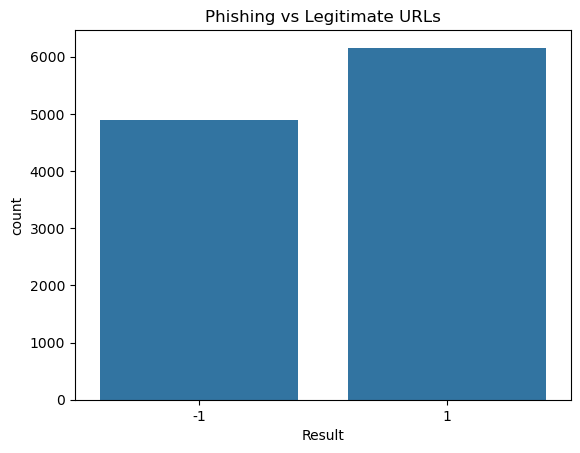

In [13]:
sns.countplot(data=df, x="Result")
plt.title("Phishing vs Legitimate URLs")
plt.show()

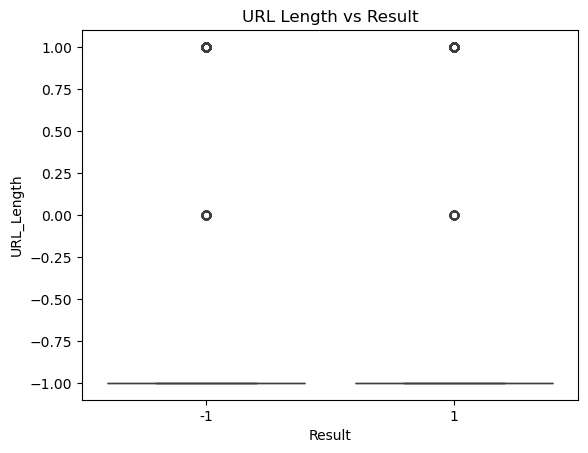

In [14]:
sns.boxplot(data=df, x="Result", y="URL_Length")
plt.title("URL Length vs Result")
plt.show()

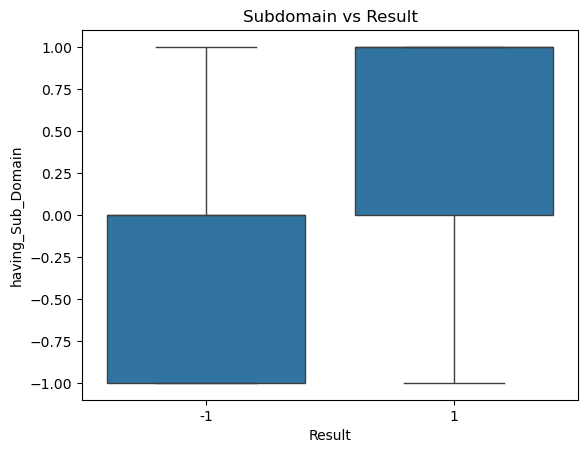

In [15]:
sns.boxplot(data=df, x="Result", y="having_Sub_Domain")
plt.title("Subdomain vs Result")
plt.show()

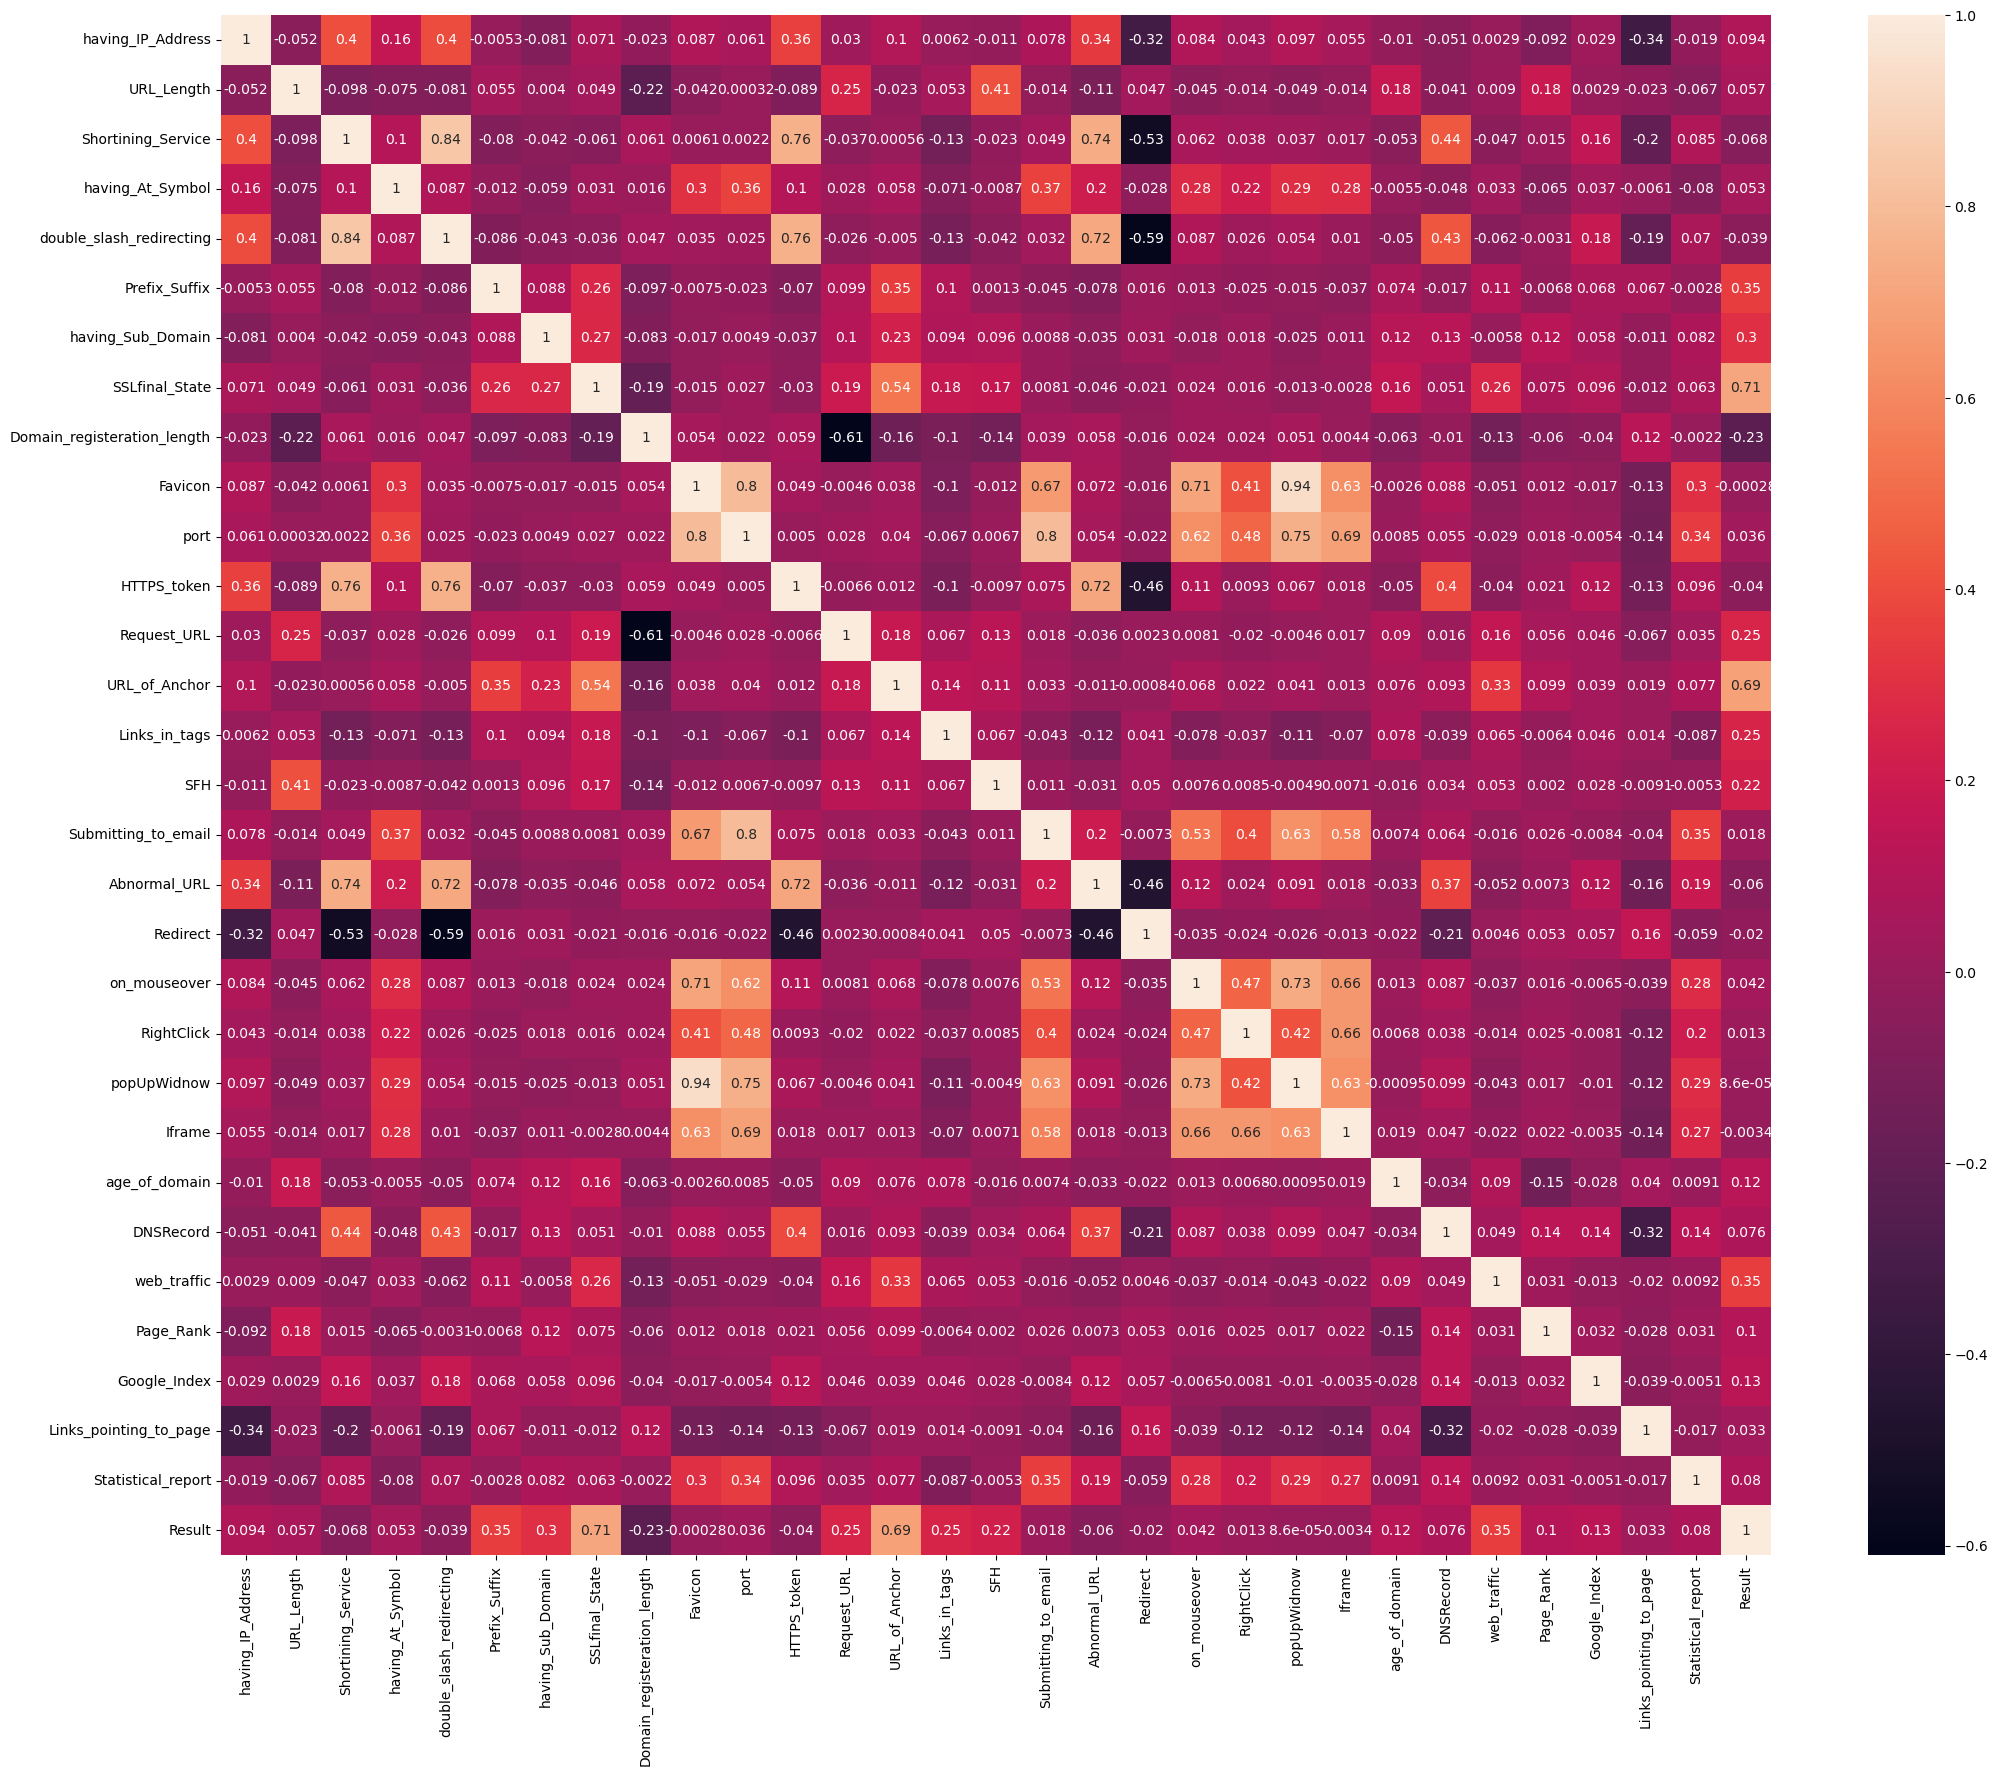

In [16]:
plt.figure(figsize=(25, 20))

sns.heatmap(
    df.corr(numeric_only=True),
    annot=True,
)

plt.show()

In [17]:
def corr(dataset , threshold):
    col_corr = set()
    corr_matrix = dataset.corr()
    for i in range(len(corr_matrix.columns)):
        for j in range(i):
            if abs(df.iloc[i,j] > threshold):
                col_corr.add(corr_matrix.columns[i])
    return col_corr           

In [18]:
corr_features=corr(df,0.75)

In [19]:
corr_features

{'Abnormal_URL',
 'DNSRecord',
 'Domain_registeration_length',
 'Favicon',
 'Google_Index',
 'HTTPS_token',
 'Iframe',
 'Links_in_tags',
 'Links_pointing_to_page',
 'Page_Rank',
 'Prefix_Suffix',
 'Redirect',
 'Request_URL',
 'Result',
 'RightClick',
 'SFH',
 'SSLfinal_State',
 'Shortining_Service',
 'Statistical_report',
 'Submitting_to_email',
 'URL_Length',
 'URL_of_Anchor',
 'age_of_domain',
 'double_slash_redirecting',
 'having_At_Symbol',
 'having_Sub_Domain',
 'on_mouseover',
 'popUpWidnow',
 'port',
 'web_traffic'}

In [20]:
print(df.shape)
print(df.columns.tolist())
print(df["Result"].value_counts())
print(df.isnull().sum().sum())
print(df.duplicated().sum())

(11055, 31)
['having_IP_Address', 'URL_Length', 'Shortining_Service', 'having_At_Symbol', 'double_slash_redirecting', 'Prefix_Suffix', 'having_Sub_Domain', 'SSLfinal_State', 'Domain_registeration_length', 'Favicon', 'port', 'HTTPS_token', 'Request_URL', 'URL_of_Anchor', 'Links_in_tags', 'SFH', 'Submitting_to_email', 'Abnormal_URL', 'Redirect', 'on_mouseover', 'RightClick', 'popUpWidnow', 'Iframe', 'age_of_domain', 'DNSRecord', 'web_traffic', 'Page_Rank', 'Google_Index', 'Links_pointing_to_page', 'Statistical_report', 'Result']
Result
 1    6157
-1    4898
Name: count, dtype: int64
0
5206


In [21]:
df.head()

,having_IP_Address,URL_Length,Shortining_Service,having_At_Symbol,double_slash_redirecting,Prefix_Suffix,having_Sub_Domain,SSLfinal_State,Domain_registeration_length,Favicon,...,popUpWidnow,Iframe,age_of_domain,DNSRecord,web_traffic,Page_Rank,Google_Index,Links_pointing_to_page,Statistical_report,Result
0,-1,1,1,1,-1,-1,-1,-1,-1,1,...,1,1,-1,-1,-1,-1,1,1,-1,-1
1,1,1,1,1,1,-1,0,1,-1,1,...,1,1,-1,-1,0,-1,1,1,1,-1
2,1,0,1,1,1,-1,-1,-1,-1,1,...,1,1,1,-1,1,-1,1,0,-1,-1
3,1,0,1,1,1,-1,-1,-1,1,1,...,1,1,-1,-1,1,-1,1,-1,1,-1
4,1,0,-1,1,1,-1,1,1,-1,1,...,-1,1,-1,-1,0,-1,1,1,1,1


In [22]:
df.dtypes

having_IP_Address              int64
URL_Length                     int64
Shortining_Service             int64
having_At_Symbol               int64
double_slash_redirecting       int64
Prefix_Suffix                  int64
having_Sub_Domain              int64
SSLfinal_State                 int64
Domain_registeration_length    int64
Favicon                        int64
port                           int64
HTTPS_token                    int64
Request_URL                    int64
URL_of_Anchor                  int64
Links_in_tags                  int64
SFH                            int64
Submitting_to_email            int64
Abnormal_URL                   int64
Redirect                       int64
on_mouseover                   int64
RightClick                     int64
popUpWidnow                    int64
Iframe                         int64
age_of_domain                  int64
DNSRecord                      int64
web_traffic                    int64
Page_Rank                      int64
G

In [24]:
features = df.columns[:-1]

In [25]:
features

Index(['having_IP_Address', 'URL_Length', 'Shortining_Service',
       'having_At_Symbol', 'double_slash_redirecting', 'Prefix_Suffix',
       'having_Sub_Domain', 'SSLfinal_State', 'Domain_registeration_length',
       'Favicon', 'port', 'HTTPS_token', 'Request_URL', 'URL_of_Anchor',
       'Links_in_tags', 'SFH', 'Submitting_to_email', 'Abnormal_URL',
       'Redirect', 'on_mouseover', 'RightClick', 'popUpWidnow', 'Iframe',
       'age_of_domain', 'DNSRecord', 'web_traffic', 'Page_Rank',
       'Google_Index', 'Links_pointing_to_page', 'Statistical_report'],
      dtype='object')

In [29]:
features_info = pd.DataFrame({
    "features" : df.columns,
    "unique_values" : [df[col].nunique() for col in df.columns],
    "missing" : [df[col].isnull().sum() for col in df.columns]
})

In [30]:
features_info

,features,unique_values,missing
0,having_IP_Address,2,0
1,URL_Length,3,0
2,Shortining_Service,2,0
3,having_At_Symbol,2,0
4,double_slash_redirecting,2,0
5,Prefix_Suffix,2,0
6,having_Sub_Domain,3,0
7,SSLfinal_State,3,0
8,Domain_registeration_length,2,0
9,Favicon,2,0


In [31]:
features_corr = df.corr()["Result"].sort_values()

In [32]:
features_corr

Domain_registeration_length   -0.225789
Shortining_Service            -0.067966
Abnormal_URL                  -0.060488
HTTPS_token                   -0.039854
double_slash_redirecting      -0.038608
Redirect                      -0.020113
Iframe                        -0.003394
Favicon                       -0.000280
popUpWidnow                    0.000086
RightClick                     0.012653
Submitting_to_email            0.018249
Links_pointing_to_page         0.032574
port                           0.036419
on_mouseover                   0.041838
having_At_Symbol               0.052948
URL_Length                     0.057430
DNSRecord                      0.075718
Statistical_report             0.079857
having_IP_Address              0.094160
Page_Rank                      0.104645
age_of_domain                  0.121496
Google_Index                   0.128950
SFH                            0.221419
Links_in_tags                  0.248229
Request_URL                    0.253372


In [44]:
c = 0;
for col in features_corr.index:
    if features_corr[(col)] > 0.7 and features_corr[(col)] < 0.9:
        c += 1


In [45]:
c

1

In [46]:
features_corr.abs().sort_values()

popUpWidnow                    0.000086
Favicon                        0.000280
Iframe                         0.003394
RightClick                     0.012653
Submitting_to_email            0.018249
Redirect                       0.020113
Links_pointing_to_page         0.032574
port                           0.036419
double_slash_redirecting       0.038608
HTTPS_token                    0.039854
on_mouseover                   0.041838
having_At_Symbol               0.052948
URL_Length                     0.057430
Abnormal_URL                   0.060488
Shortining_Service             0.067966
DNSRecord                      0.075718
Statistical_report             0.079857
having_IP_Address              0.094160
Page_Rank                      0.104645
age_of_domain                  0.121496
Google_Index                   0.128950
SFH                            0.221419
Domain_registeration_length    0.225789
Links_in_tags                  0.248229
Request_URL                    0.253372


In [51]:
df["having_IP_Address"].value_counts()

having_IP_Address
 1    7262
-1    3793
Name: count, dtype: int64

In [48]:
pd.crosstab(
    df["having_IP_Address"],df["Result"],normalize="index"
)*100

Result,-1,1
having_IP_Address,,
-1,50.777748,49.222252
1,40.925365,59.074635


In [50]:
df.dtypes

having_IP_Address              int64
URL_Length                     int64
Shortining_Service             int64
having_At_Symbol               int64
double_slash_redirecting       int64
Prefix_Suffix                  int64
having_Sub_Domain              int64
SSLfinal_State                 int64
Domain_registeration_length    int64
Favicon                        int64
port                           int64
HTTPS_token                    int64
Request_URL                    int64
URL_of_Anchor                  int64
Links_in_tags                  int64
SFH                            int64
Submitting_to_email            int64
Abnormal_URL                   int64
Redirect                       int64
on_mouseover                   int64
RightClick                     int64
popUpWidnow                    int64
Iframe                         int64
age_of_domain                  int64
DNSRecord                      int64
web_traffic                    int64
Page_Rank                      int64
G

In [ ]:
def features)analysis